# Transaction Fraud: Exploration and Model
This notebook works through the four questions of the Capital One Recruiting data science challenge (load, plot, duplicate transactions, fraud model) on the public transactions data set. The reusable code lives in the `card_risk` package; this notebook is the exploration and the reasoning.

## 0. Setup

In [1]:
# Common imports
import numpy as np
import pandas as pd

import os

# The notebooks live in notebooks/; work from the project root so the config paths resolve.
working_directory = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(working_directory)

# To make this notebook's output stable across runs
np.random.seed(42)

# To see the columns in our DataFrames
pd.options.display.max_columns = 500

# To plot pretty figures
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12
import seaborn as sns; sns.set()

def save_fig(fig_id, tight_layout=True, fig_extension="png",
             verbose=True, resolution=300):
    path = os.path.join(working_directory, "images", fig_id + "." + fig_extension)
    os.makedirs(os.path.dirname(path), exist_ok=True)
    if verbose:
        print("Saving figure", fig_id)
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

## 1. Get the Data

Question 1: Load
- Programmatically download and load into your favorite analytical tool the transactions data. This data, which is in line-delimited JSON format, can be found here
- Please describe the structure of the data. Number of records and fields in each record?
- Please provide some additional basic summary statistics for each field. Be sure to include a count of null, minimum, maximum, and unique values where appropriate.

`load_transactions_data` only downloads the zip if `data/raw/transactions.txt` isn't already there, parses the line-delimited JSON, fixes the types (dates, ints, booleans, empty strings to nulls), sorts by transaction time and caches a parquet file so later runs are quick.

In [2]:
from card_risk.config import load_config
from card_risk.data_utils import load_transactions_data, summarize_fields

config = load_config()

In [3]:
%%time
df = load_transactions_data(config)

CPU times: user 184 ms, sys: 52.8 ms, total: 236 ms
Wall time: 127 ms


In [4]:
df.shape

(786363, 23)

There are 786,363 records. The raw file has 29 fields; six of them (`echoBuffer`, `merchantCity`, `merchantState`, `merchantZip`, `posOnPremises`, `recurringAuthInd`) are empty strings for every record, so the loader drops them and we are left with 23.

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 786363 entries, 0 to 786362
Data columns (total 23 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   accountNumber             786363 non-null  int64         
 1   customerId                786363 non-null  int64         
 2   creditLimit               786363 non-null  float64       
 3   availableMoney            786363 non-null  float64       
 4   transactionDateTime       786363 non-null  datetime64[ns]
 5   transactionAmount         786363 non-null  float64       
 6   merchantName              786363 non-null  object        
 7   acqCountry                781801 non-null  object        
 8   merchantCountryCode       785639 non-null  object        
 9   posEntryMode              782309 non-null  object        
 10  posConditionCode          785954 non-null  object        
 11  merchantCategoryCode      786363 non-null  object        
 12  cu

In [6]:
df.head()

,accountNumber,customerId,creditLimit,availableMoney,transactionDateTime,transactionAmount,merchantName,acqCountry,merchantCountryCode,posEntryMode,posConditionCode,merchantCategoryCode,currentExpDate,accountOpenDate,dateOfLastAddressChange,cardCVV,enteredCVV,cardLast4Digits,transactionType,currentBalance,cardPresent,expirationDateKeyInMatch,isFraud
0,419104777,419104777,50000.0,50000.0,2016-01-01 00:01:02,44.09,Washington Post,US,US,09,01,subscriptions,2028-03-01,2015-05-30,2015-05-30,837,837,5010,PURCHASE,0.0,False,False,0
1,674577133,674577133,5000.0,5000.0,2016-01-01 00:01:44,329.57,staples.com,US,US,09,08,online_retail,2024-10-01,2015-08-19,2015-08-19,430,430,1693,PURCHASE,0.0,False,False,0
2,958438658,958438658,20000.0,20000.0,2016-01-01 00:01:47,164.57,cheapfast.com,US,US,05,01,online_retail,2023-04-01,2013-07-20,2013-07-20,445,445,2062,PURCHASE,0.0,False,False,0
3,851126461,851126461,10000.0,10000.0,2016-01-01 00:02:04,122.83,discount.com,US,US,02,08,online_retail,2025-07-01,2014-10-18,2014-10-18,667,667,7359,PURCHASE,0.0,False,False,0
4,148963316,148963316,2500.0,2500.0,2016-01-01 00:02:19,0.00,Fast Repair,US,US,05,01,auto,2026-12-01,2013-12-12,2013-12-12,542,542,1785,ADDRESS_VERIFICATION,0.0,False,False,0


In [7]:
df.tail()

,accountNumber,customerId,creditLimit,availableMoney,transactionDateTime,transactionAmount,merchantName,acqCountry,merchantCountryCode,posEntryMode,posConditionCode,merchantCategoryCode,currentExpDate,accountOpenDate,dateOfLastAddressChange,cardCVV,enteredCVV,cardLast4Digits,transactionType,currentBalance,cardPresent,expirationDateKeyInMatch,isFraud
786358,690351684,690351684,7500.0,6007.68,2016-12-30 23:57:33,128.84,EZ Putt Putt #551896,US,US,09,01,entertainment,2032-12-01,2015-02-26,2015-02-26,380,380,6106,PURCHASE,1492.32,True,False,0
786359,365766122,365766122,7500.0,970.87,2016-12-30 23:58:25,49.47,alibaba.com,US,US,90,01,online_retail,2030-07-01,2015-01-19,2016-10-06,479,479,1194,PURCHASE,6529.13,False,False,0
786360,543902721,543902721,1000.0,767.70,2016-12-30 23:59:33,13.02,abc.com,US,US,05,08,online_subscriptions,2023-02-01,2012-02-11,2012-02-11,743,743,4157,PURCHASE,232.30,False,False,0
786361,912493707,912493707,5000.0,4991.10,2016-12-30 23:59:35,8.85,Play Store,US,US,09,08,mobileapps,2028-03-01,2012-09-28,2016-10-31,284,284,9972,PURCHASE,8.90,False,False,0
786362,152973583,152973583,15000.0,7195.76,2016-12-30 23:59:45,169.07,Burger King #06782,US,US,09,01,fastfood,2020-06-01,2014-11-24,2016-08-19,141,141,8731,PURCHASE,7804.24,True,False,0


Looks sorted! For the summary statistics, here is the null count, unique count, min and max for every field.

In [8]:
summarize_fields(df)

,dtype,null_count,unique_count,min,max
accountNumber,int64,0,5000,100088067,999389635
customerId,int64,0,5000,100088067,999389635
creditLimit,float64,0,10,250.0,50000.0
availableMoney,float64,0,521915,-1005.63,50000.0
transactionDateTime,datetime64[ns],0,776637,2016-01-01 00:01:02,2016-12-30 23:59:45
transactionAmount,float64,0,66038,0.0,2011.54
merchantName,object,0,2490,NaN,NaN
acqCountry,object,4562,4,NaN,NaN
merchantCountryCode,object,724,4,NaN,NaN
posEntryMode,object,4054,5,NaN,NaN


In [9]:
df.describe()

,accountNumber,customerId,creditLimit,availableMoney,transactionDateTime,transactionAmount,currentExpDate,accountOpenDate,dateOfLastAddressChange,cardCVV,enteredCVV,cardLast4Digits,currentBalance,isFraud
count,7.863630e+05,7.863630e+05,786363.000000,786363.000000,786363,786363.000000,786363,786363,786363,786363.000000,786363.000000,786363.000000,786363.000000,786363.000000
mean,5.372326e+08,5.372326e+08,10759.464459,6250.725369,2016-07-06 01:58:58.395681280,136.985791,2026-09-25 23:50:42.724542464,2014-02-03 01:11:17.352826368,2015-04-14 06:46:41.127723264,544.467338,544.183857,4757.417799,4508.739089,0.015790
min,1.000881e+08,1.000881e+08,250.000000,-1005.630000,2016-01-01 00:01:02,0.000000,2019-12-01 00:00:00,1989-08-22 00:00:00,1989-08-22 00:00:00,100.000000,0.000000,0.000000,0.000000,0.000000
25%,3.301333e+08,3.301333e+08,5000.000000,1077.420000,2016-04-06 19:35:07,33.650000,2023-05-01 00:00:00,2013-06-29 00:00:00,2014-10-08 00:00:00,310.000000,310.000000,2178.000000,689.910000,0.000000
50%,5.074561e+08,5.074561e+08,7500.000000,3184.860000,2016-07-08 05:03:57,87.900000,2026-10-01 00:00:00,2014-09-05 00:00:00,2016-01-13 00:00:00,535.000000,535.000000,4733.000000,2451.760000,0.000000
75%,7.676200e+08,7.676200e+08,15000.000000,7500.000000,2016-10-05 13:52:03.500000,191.480000,2030-03-01 00:00:00,2015-05-04 00:00:00,2016-06-06 00:00:00,785.000000,785.000000,7338.000000,5291.095000,0.000000
max,9.993896e+08,9.993896e+08,50000.000000,50000.000000,2016-12-30 23:59:45,2011.540000,2033-08-01 00:00:00,2015-12-31 00:00:00,2016-12-30 00:00:00,998.000000,998.000000,9998.000000,47498.810000,1.000000
std,2.554211e+08,2.554211e+08,11636.174890,8880.783989,NaN,147.725569,NaN,NaN,NaN,261.524220,261.551254,2996.583810,6457.442068,0.124664


A few things stand out. `acqCountry`, `merchantCountryCode`, `posEntryMode`, `posConditionCode` and `transactionType` have a few thousand nulls each. The data covers 2016, and the label is imbalanced:

In [10]:
df["isFraud"].mean()

np.float64(0.01579041740264992)

About 1.6% of transactions are fraud.

## 2. Initial Exploration

Question 2: Plot
- Plot a histogram of the processed amounts of each transaction, the transactionAmount column.
- Report any structure you find and any hypotheses you have about that structure.

Saving figure transaction_amount_histogram


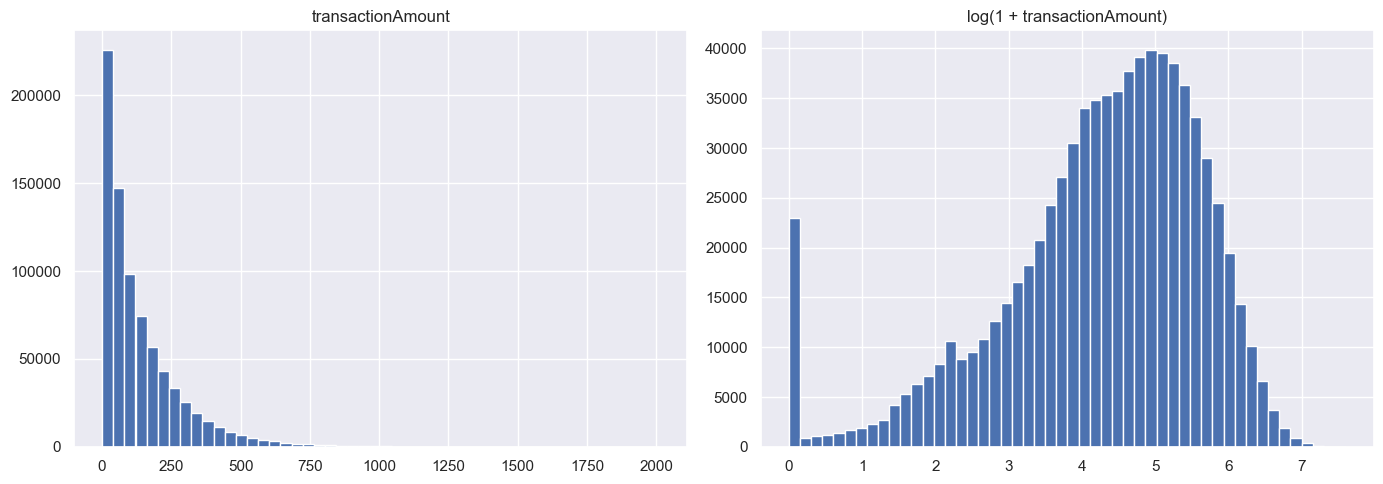

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
df["transactionAmount"].hist(bins=50, ax=axes[0])
axes[0].set_title("transactionAmount")
np.log1p(df["transactionAmount"]).hist(bins=50, ax=axes[1])
axes[1].set_title("log(1 + transactionAmount)")
save_fig("transaction_amount_histogram")
plt.show()

In [12]:
df["transactionAmount"].describe()

count    786363.000000
mean        136.985791
std         147.725569
min           0.000000
25%          33.650000
50%          87.900000
75%         191.480000
max        2011.540000
Name: transactionAmount, dtype: float64

In [13]:
(df["transactionAmount"] == 0).mean()

np.float64(0.028263028652161914)

The amounts are heavily right skewed: the median is far below the mean and there is a long tail out past $1,000. On the log scale the bulk looks roughly bell shaped, so amounts are close to log-normal, which is typical of purchase sizes. There is also a spike at exactly zero (about 3% of transactions); my hypothesis is that these are address verification and card-check transactions rather than purchases, which we can check:

In [14]:
df.loc[df["transactionAmount"] == 0, "transactionType"].value_counts()

transactionType
ADDRESS_VERIFICATION    20169
PURCHASE                 1484
REVERSAL                  572
Name: count, dtype: int64

That agrees with the hypothesis. If I were modelling amounts directly I'd use a log transform, but the tree models below don't need it.

### 2.1 A Few Checks

First, I am curious to see if the `accountNumber` is the same as `customerId` or if customers can have multiple accounts.

In [15]:
(df["accountNumber"] == df["customerId"]).all()

np.True_

They are the same identifier. Next, `creditLimit`, `availableMoney` and `currentBalance` look related.

In [16]:
np.isclose(df["currentBalance"] + df["availableMoney"], df["creditLimit"]).all()

np.True_

So `currentBalance` + `availableMoney` == `creditLimit`, which agrees with intuition. The next feature of interest is whether the entered CVV is different from the card's CVV.

In [17]:
(df["enteredCVV"] == df["cardCVV"]).mean()

np.float64(0.9910791835322873)

In [18]:
df.groupby(df["enteredCVV"] == df["cardCVV"])["isFraud"].mean()

False    0.028938
True     0.015672
Name: isFraud, dtype: float64

Most of the time these match, and the fraud rate is noticeably higher when they don't, so `CVV_match` should be a useful feature. Another idea is small transactions: fraud on an account often starts with small "test" charges.

In [19]:
(df["transactionAmount"] < 1).mean()

np.float64(0.034139449592618165)

In [20]:
df.groupby(df["transactionAmount"] < 1)["isFraud"].mean()

transactionAmount
False    0.016167
True     0.005140
Name: isFraud, dtype: float64

Interesting, it's the opposite of what I expected: transactions under a dollar are *less* likely to be fraud (about 0.5% vs 1.6%), probably because most of them are zero-dollar address verifications. I still keep a feature counting a customer's previous small transactions, since the "test charge then big purchase" pattern is about the sequence, not the small transaction itself, and the model can decide whether it helps.

## 3. Duplicate Transactions

Question 3: Data Wrangling - Duplicate Transactions
You will notice a number of what look like duplicated transactions in the data set. One type of duplicated transaction is a reversed transaction, where a purchase is followed by a reversal. Another example is a multi-swipe, where a vendor accidentally charges a customer's card multiple times within a short time span.
- Can you programmatically identify reversed and multi-swipe transactions?
- What total number of transactions and total dollar amount do you estimate for the reversed transactions? For the multi-swipe transactions? (please consider the first transaction to be "normal" and exclude it from the number of transaction and dollar amount counts)
- Did you find anything interesting about either kind of transaction?

In [21]:
df["transactionType"].value_counts(dropna=False)

transactionType
PURCHASE                745193
REVERSAL                 20303
ADDRESS_VERIFICATION     20169
None                       698
Name: count, dtype: int64

Reversals are straightforward since `transactionType` labels them.

In [22]:
from card_risk.data_utils import (
    identify_reversed_transactions,
    identify_multi_swipe_transactions,
    summarize_duplicate_transactions,
)

In [23]:
reversals = df[identify_reversed_transactions(df)]
reversals.shape[0], reversals["transactionAmount"].sum()

(20303, np.float64(2821792.5000000005))

There are 20,303 reversals worth about $2.82 million. Do reversals sit right under the transaction being reversed? Let's look at the customer with the most reversals.

In [24]:
top_customer = reversals["customerId"].value_counts().index[0]
df.loc[df["customerId"] == top_customer, ["transactionDateTime", "merchantName", "transactionAmount", "transactionType"]].head(15)

,transactionDateTime,merchantName,transactionAmount,transactionType
7,2016-01-01 00:06:17,Fresh Flowers,96.68,PURCHASE
20,2016-01-01 00:14:21,Next Day eCards,339.52,PURCHASE
29,2016-01-01 00:16:58,Blue Mountain Online Services,33.40,PURCHASE
42,2016-01-01 00:23:10,Blue Mountain Online Services,168.80,PURCHASE
43,2016-01-01 00:25:04,Blue Mountain Online Services,259.26,PURCHASE
68,2016-01-01 00:40:15,Blue Mountain eCards,0.00,ADDRESS_VERIFICATION
100,2016-01-01 01:03:46,Blue Mountain eCards,105.78,PURCHASE
116,2016-01-01 01:13:09,Next Day eCards,41.75,PURCHASE
141,2016-01-01 01:31:20,Blue Mountain eCards,82.70,PURCHASE
148,2016-01-01 01:34:10,Fresh eCards,622.52,PURCHASE


Reversals do not always follow the purchase immediately, so matching them to the original purchase needs the customer, merchant and amount rather than just the previous row.

For multi-swipes, I call a purchase a multi-swipe if the same customer was charged the same amount at the same merchant within 3 minutes of the previous such charge. The first swipe is treated as normal and not counted, as the prompt asks. The window is a judgement call, so let's see how sensitive the count is to it.

In [25]:
for window_seconds in [60, 180, 300, 600]:
    multi_swipes = identify_multi_swipe_transactions(df, window_seconds)
    print(window_seconds, multi_swipes.sum(), round(df.loc[multi_swipes, "transactionAmount"].sum(), 2))

60 2538 377855.13
180 7679 1104006.71


300 7680 1104006.71
600 7682 1104217.97


In [26]:
summarize_duplicate_transactions(df)

,count,total_amount,fraud_rate
reversal,20303.0,2821792.50,0.016599
multi_swipe,7679.0,1104006.71,0.017060


With a 3 minute window there are 7,679 multi-swipes worth about $1.10 million, and the count is fairly stable between 3 and 10 minutes, so the choice of window isn't driving the answer. Interestingly, neither kind of duplicate is much more likely to be fraud than an ordinary transaction (fraud rates of about 1.7% vs 1.6% overall), so they look like data quality / merchant processing issues rather than a fraud signal. In a production pipeline I'd remove multi-swipes before modelling spend, but I keep them for the fraud model since they are real authorization attempts we would have to score.

## 4. Feature Engineering

The features are built by `card_risk.features.build_transaction_features`. Everything that summarizes a customer's history uses only **earlier** transactions (an expanding window over the shifted series), so nothing leaks from the future. The groups of features:
- **Time**: hour, minute, second, day of week, weekend, night. I left out month and quarter on purpose: with one year of data they are confounded with time and wouldn't generalize to next year.
- **Expanding history**: count, mean, median, std, min and max of the customer's previous amounts, and of the days between their transactions.
- **Trends**: current amount minus previous amount, mean, median, min, max.
- **Rolling windows**: 2, 3, 5 and 25 transaction rolling stats and their ratio to the customer's overall history.
- **Velocity**: number and dollar amount of transactions in the last hour and last 24 hours.
- **Merchants**: first time at this merchant, number of distinct merchants so far. Merchant names have the location number trimmed (e.g. "AMC #191138" becomes "AMC"), which takes the one-hot encoding from about 2,500 columns down to a couple of hundred.
- **Account**: utilization, transaction as a share of the limit and of available money, CVV match, days since address change, days until expiration, foreign merchant.

`cardCVV`, `enteredCVV` and `cardLast4Digits` are identifiers, not quantities, so they are not features themselves.

In [27]:
from card_risk.features import build_transaction_features, NUM_FEATURES, CAT_FEATURES

In [28]:
%%time
df_features = build_transaction_features(df)

CPU times: user 7.94 s, sys: 1.09 s, total: 9.03 s
Wall time: 9.2 s


In [29]:
df_features.shape

(786363, 108)

In [30]:
len(NUM_FEATURES), len(CAT_FEATURES)

(98, 7)

Let's spot check one customer to make sure the history features only use the past.

In [31]:
one_customer = df_features[df_features["customerId"] == df_features["customerId"].iloc[1000]]
one_customer[["transactionDateTime", "transactionAmount", "previous_transactions_count",
              "previous_amounts_mean", "previous_transaction_amt", "transactions_last_24h"]].head(8)

,transactionDateTime,transactionAmount,previous_transactions_count,previous_amounts_mean,previous_transaction_amt,transactions_last_24h
195,2016-01-01 02:08:56,245.509995,0.0,NaN,NaN,1.0
212,2016-01-01 02:20:24,113.010002,1.0,245.509995,245.509995,2.0
510,2016-01-01 05:59:28,21.450001,2.0,179.259995,113.010002,3.0
517,2016-01-01 06:05:08,41.860001,3.0,126.656670,21.450001,4.0
679,2016-01-01 08:01:59,42.139999,4.0,105.457497,41.860001,5.0
767,2016-01-01 09:13:14,664.750000,5.0,92.793999,42.139999,6.0
1000,2016-01-01 11:58:43,382.920013,6.0,188.119995,664.750000,7.0
1095,2016-01-01 13:11:01,12.130000,7.0,215.948578,382.920013,8.0


The first transaction has no history, and each row's `previous_amounts_mean` is the average of the rows above it. Looks right! (The unit tests in `tests/test_features.py` check this, and that changing a later transaction never changes earlier features.)

## 5. Split Out of Time, Then Explore

Before we do any more analysis we should separate the test set; the human brain is an excellent pattern detection system and proper ML hygiene says not to look at it.

A random `train_test_split` has a subtle leakage problem with transactional data: if there is a fraud wave at a particular point in time, a tree model can learn that "macro" fraud rate from transactions on both sides of the split and the test score looks better than it would in production. So I use an out-of-time split: the most recent 5% of transactions (mid to late December) is the test set, and the 5% before that is a validation set for early stopping and for choosing the threshold.

One note on the original version of this notebook: after feature engineering the data was sorted by customer, so slicing the first 95% of rows actually split by customer, not by time. Here `out_of_time_split` sorts by `transactionDateTime` first.

The drawback is that the test set is all December, when people spend the most. With only one year of data I still think this is the honest estimate.

In [32]:
from card_risk.fraud.data import load_fraud_model_splits

splits = load_fraud_model_splits(config)
{name: (split.shape[0], split["transactionDateTime"].min(), split["transactionDateTime"].max())
 for name, split in splits.items() if name != "train_full"}

{'train': (709691,
  Timestamp('2016-01-01 00:01:02'),
  Timestamp('2016-11-27 15:29:58')),
 'valid': (37353,
  Timestamp('2016-11-27 15:30:27'),
  Timestamp('2016-12-13 21:16:58')),
 'test': (39319,
  Timestamp('2016-12-13 21:17:22'),
  Timestamp('2016-12-30 23:59:45'))}

Let's make a copy of the training data for exploration and sample it to keep the calculations quick.

In [33]:
df_explore = splits["train"].copy()
df_explore = df_explore.sample(10000, random_state=42)

First the linear correlation (Pearson's r) of each numeric feature with the label.

In [34]:
corr_matrix = df_explore[NUM_FEATURES + ["isFraud"]].corr(numeric_only=True)
corr_matrix["isFraud"].sort_values(ascending=False).head(15)

isFraud                                         1.000000
delta_most_recent_transaction_amt_min_amt       0.098186
delta_most_recent_transaction_amt_median_amt    0.096522
transactionAmount                               0.096388
delta_most_recent_transaction_amt_mean_amt      0.095126
delta_most_recent_amt_prev_amt                  0.079346
amount_last_1h                                  0.072893
moving_2_transaction_mean_amt                   0.058787
amount_velocity                                 0.056910
moving_2_transaction_max_amt                    0.056254
moving_3_transaction_mean_amt                   0.055167
moving_3_transaction_max_amt                    0.050656
moving_5_transaction_mean_amt                   0.049417
ratio_2_recent_to_overall_mean_amt              0.047027
moving_5_transaction_max_amt                    0.043680
Name: isFraud, dtype: float64

In [35]:
corr_matrix["isFraud"].sort_values().head(10)

cardPresent                        -0.049846
is_amount_less_dollar              -0.020663
moving_25_transaction_mean_days    -0.020571
is_weekend                         -0.020319
moving_5_transaction_mean_days     -0.019767
moving_3_transaction_mean_days     -0.019466
moving_2_transaction_mean_days     -0.019457
days_between_transactions_median   -0.019206
moving_2_transaction_max_days      -0.019136
moving_5_transaction_min_days      -0.019084
Name: isFraud, dtype: float64

Even though we have a lot of features it is worth looking at scatter plots of the most correlated ones.

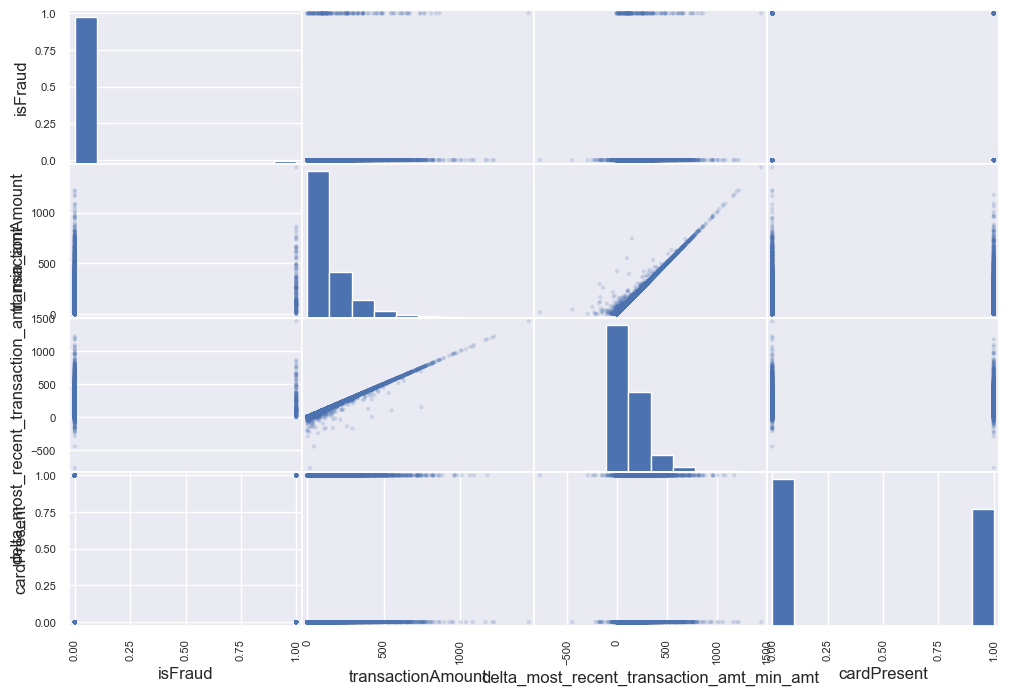

In [36]:
from pandas.plotting import scatter_matrix

attributes = [
    "isFraud",
    "transactionAmount",
    "delta_most_recent_transaction_amt_min_amt",
    "cardPresent",
]
scatter_matrix(df_explore[attributes], figsize=(12, 8), alpha=0.2)
plt.show()

None of the linear correlations is large, which is typical for fraud: the signal is in combinations and thresholds (card not present *and* a large amount, unusual merchant *and* a burst of activity), which is what tree ensembles are good at. Larger amounts and card-not-present transactions are the clearest single signals.

## 6. Model

Question 4: Model
Fraud is a problem for any bank. Fraud can take many forms, whether it is someone stealing a single credit card, to large batches of stolen credit card numbers being used on the web, or even a mass compromise of credit card numbers stolen from a merchant via tools like credit card skimming devices.
Each of the transactions in the dataset has a field called isFraud. Please build a predictive model to determine whether a given transaction will be fraudulent or not. Use as much of the data as you like (or all of it).
Provide an estimate of performance using an appropriate sample, and show your work.
Please explain your methodology (modeling algorithm/method used and why, what features/data you found useful, what questions you have, and what you would do next with more time)

The training is done by the pipeline commands (`make fraud`), which run:
1. `fraud-baselines`: logistic regression, random forest and XGBoost compared with `TimeSeriesSplit` cross validation,
2. `fraud-tune` (optional): randomized hyperparameter search, again with time-series folds,
3. `fraud-train`: the final XGBoost with early stopping on the validation month; the threshold is chosen on validation for 80% recall,
4. `fraud-evaluate`: metrics, plots and SHAP on the out-of-time test set.

Here I load the saved model and look at the results.

In [37]:
from card_risk.fraud import FraudModel
from card_risk.evaluation import compute_binary_classification_metrics, summarize_score_deciles

model = FraudModel.load(config.paths.model_dir)
df_test = splits["test"]
y_test = df_test["isFraud"]
xgb_preds = model.predict_proba(df_test)

In [38]:
baselines_path = config.paths.reports_dir / "fraud" / "baselines.csv"
pd.read_csv(baselines_path, index_col=0) if baselines_path.exists() else "run fraud-baselines to compare models"

,fold_1,fold_2,fold_3,fold_4,fold_5,mean,std
xgboost,0.762175,0.806883,0.809351,0.834689,0.828939,0.808407,0.025507
logistic_regression,0.744933,0.766773,0.760400,0.781560,0.775987,0.765930,0.012788
random_forest,0.732887,0.748569,0.762210,0.766378,0.766322,0.755273,0.012958


In [39]:
compute_binary_classification_metrics(y_test, xgb_preds, model.threshold)

{'n': 39319,
 'positive_rate': 0.014369643175055317,
 'roc_auc': 0.8382761745176404,
 'gini': 0.6765523490352807,
 'pr_auc': 0.24529663445437142,
 'ks': 0.5176054906807223,
 'brier': 0.01223397670720469,
 'mean_predicted': 0.013458090834319592,
 'threshold': 0.01281553041189909,
 'alert_rate': 0.2607899488796765,
 'precision': 0.04193485469085235,
 'recall': 0.7610619469026548,
 'f1': 0.0794897864867363}

On the out-of-time test set the model has a ROC AUC of about 0.84 (and a PR AUC of about 0.25, against a 1.4% base rate). The threshold was picked on the validation set to catch 80% of fraud; on the test month it catches about 76% of fraudulent transactions and about 85% of fraud dollars (it is better at catching the large ones, which is what matters for losses), while flagging about a quarter of transactions. The precision is low, about 4%, which is the price of high recall at a 1.4% base rate. In practice that threshold is a business decision made with the fraud operations and risk teams, trading customer friction against losses, and not something to optimize in isolation.

In [40]:
from card_risk.evaluation.plots import plot_precision_recall_vs_threshold, plot_roc_curve

plot_precision_recall_vs_threshold(y_test, xgb_preds, "Precision Recall Tradeoff for XGBoost", model.threshold)
plt.show()

In [41]:
plot_roc_curve(y_test, xgb_preds, "ROC for XGBoost Classifier (out of time)", label="XGBoost")
plt.show()

In [42]:
summarize_score_deciles(y_test, xgb_preds)

,n,min_score,max_score,mean_predicted,observed_rate,share_of_positives
bin,,,,,,
1,3932,0.000052,0.000545,0.000286,0.000000,0.000000
2,3932,0.000545,0.002062,0.001267,0.000763,0.005310
3,3932,0.002062,0.003392,0.002738,0.003052,0.021239
4,3932,0.003393,0.004676,0.004033,0.006104,0.042478
5,3932,0.004677,0.006164,0.005394,0.003815,0.026549
6,3931,0.006165,0.008105,0.007086,0.007123,0.049558
7,3932,0.008105,0.011088,0.009479,0.008393,0.058407
8,3932,0.011089,0.016642,0.013523,0.013479,0.093805
9,3932,0.016642,0.029583,0.022109,0.023652,0.164602


The rank ordering is good: the observed fraud rate climbs almost steadily by score decile, and the top decile alone holds about 54% of the fraud. Now let's see what drives the model with SHAP.

In [43]:
import xgboost as xgb
import shap

examples = model.transform(df_test.sample(5000, random_state=42))
shap_values = model.classifier.get_booster().predict(
    xgb.DMatrix(examples), pred_contribs=True,
    iteration_range=(0, model.classifier.best_iteration + 1))[:, :-1]
shap.summary_plot(shap_values, examples, max_display=20)

In [44]:
shap.dependence_plot("transactionAmount", shap_values, examples, interaction_index="cardPresent")

Transaction amount is the strongest driver, and the probability of fraud rises with the amount; the effect is stronger when the card is not present, which agrees with intuition (card-not-present fraud on stolen numbers). How a transaction compares with the customer's own history (difference from their smallest and typical amounts) and the point-of-sale entry mode also matter.

## 7. Summary and Thoughts on Further Work

- **Load and plot:** 786,363 transactions, 23 informative fields after dropping 6 empty ones, 1.6% fraud. Transaction amounts are close to log-normal with a spike at zero from address verification transactions.
- **Duplicates:** 20,303 reversals ($2.82M) and 7,679 multi-swipes ($1.10M, 3 minute window); neither is much more likely to be fraud.
- **Model:** XGBoost on about 100 leak-free history, velocity and account features plus one-hot merchant and point-of-sale categories. Out-of-time test ROC AUC about 0.84; at the threshold chosen on validation it catches about 76% of fraud transactions and 85% of fraud dollars. Hyperparameters matter: the heavily regularized settings from my first pass (min_child_weight 500, gamma 10) gave a validation AUC of 0.78 vs 0.85 for these.

With more time I would:
- do a round of feature selection by SHAP importance, adding features in groups until the validation AUC stops improving, for a leaner model that is as accurate;
- add merchant-level and merchant-category risk features (e.g. recent fraud rate at the merchant, computed out of time) and network features linking customers through shared merchants, which is how compromised merchants show up;
- calibrate the threshold on dollars and customer friction with the fraud operations team rather than a recall target;
- monitor the score distribution and feature drift month to month once in production.